In [ ]:



import builtins
from pyspark.sql.functions import round ,col,desc

import os

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType,StructField,StringType, TimestampType, DoubleType

# winows
os.environ['PYSPARK_SUBMIT_ARGS'] = '--driver-mmory 3g pyshark-shell'

spark = SparkSession.builder.appName("CITI-BIKE").master('local[2]').config('spark.driver.memory','3g').config('spark.executor.memory','3g').config('spark.sql.shuffle.partitions','10').getOrCreate()

citi_bike_schema = StructType([
    StructField('ride_id',StringType(),True),
    StructField('rideable_type',StringType(),True),
    StructField('started_at',TimestampType(),True),
    StructField('ended_at',TimestampType(),True),
    StructField('start_station_name',StringType(),True),
    StructField('start_station_id',StringType(),True),
    StructField('end_station_name',StringType(),True),
    StructField('end_station_id',StringType(),True),
    StructField('start_lat',DoubleType(),True),
    StructField('start_lng',DoubleType(),True),
    StructField('end_lat',DoubleType(),True),
    StructField('end_lng',DoubleType(),True),
    StructField('member_casual',StringType(),True),
    
])

df = spark.read.schema(citi_bike_schema).option('header','true').csv('../data/2023-citibike-tripdata_*/*.csv')
raw_df = spark.read.option('header','true').csv('../data/2023-citibike-tripdata_/*/*.csv')

df.show(3)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/19 08:09:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/19 08:09:31 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: ../input/datasets/achref999/2023-citi-bike/2023-citibike-tripdata/*/*.csv.
java.io.FileNotFoundException: File ../input/datasets/achref999/2023-citi-bike/2023-citibike-tripdata/*/*.csv does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:917)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1238)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:907)
	at org.apache.hadoop.fs.FilterFileSy

+----------------+-------------+--------------------+--------------------+------------------+----------------+--------------------+--------------+-----------------+------------------+-----------------+------------------+-------------+
|         ride_id|rideable_type|          started_at|            ended_at|start_station_name|start_station_id|    end_station_name|end_station_id|        start_lat|         start_lng|          end_lat|           end_lng|member_casual|
+----------------+-------------+--------------------+--------------------+------------------+----------------+--------------------+--------------+-----------------+------------------+-----------------+------------------+-------------+
|A8518A6C4BE513DE| classic_bike|2023-01-03 23:14:...|2023-01-03 23:33:...|   E 1 St & Bowery|         5636.13|Spruce St & Nassa...|       5137.10|40.72486122254819|-73.99213135242462|      40.71146364|      -74.00552427|       casual|
|A3911E4F5B9B5773|electric_bike|2023-01-07 07:57:...|2023-01

In [4]:
df.printSchema()





root
 |-- ride_id: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- started_at: timestamp (nullable = true)
 |-- ended_at: timestamp (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- start_station_id: string (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- end_station_id: string (nullable = true)
 |-- start_lat: double (nullable = true)
 |-- start_lng: double (nullable = true)
 |-- end_lat: double (nullable = true)
 |-- end_lng: double (nullable = true)
 |-- member_casual: string (nullable = true)



In [5]:
df.count()

35106986

### We are starting off with 35106986 raw records

In [6]:
df.columns

['ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual']

In [7]:
df.describe('rideable_type','start_station_name','start_station_id','end_station_name','end_station_id','member_casual').show()

26/10/19 08:10:03 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-------------+--------------------+------------------+--------------------+-----------------+-------------+
|summary|rideable_type|  start_station_name|  start_station_id|    end_station_name|   end_station_id|member_casual|
+-------+-------------+--------------------+------------------+--------------------+-----------------+-------------+
|  count|     35106986|            35088788|          35088788|            35007079|         35007079|     35106986|
|   mean|         NULL|                NULL| 6001.514396896524|                NULL|5997.006354900131|         NULL|
| stddev|         NULL|                NULL|1127.8297273339383|                NULL|1126.838189479245|         NULL|
|    min| classic_bike|    1 Ave & E 110 St|           2733.03|    1 Ave & E 110 St|       190 Morgan|       casual|
|    max|electric_bike|York St & Marin Blvd|            SYS039|York St & Marin Blvd|     Shop Morgan |       member|
+-------+-------------+--------------------+------------------+-

In [8]:
df.describe('started_at','ended_at','start_lat','start_lng','end_lat','end_lng').show()

+-------+-------------------+--------------------+--------------------+-------------------+
|summary|          start_lat|           start_lng|             end_lat|            end_lng|
+-------+-------------------+--------------------+--------------------+-------------------+
|  count|           35088788|            35088788|            35007680|           35007680|
|   mean| 40.739814190957006|  -73.97276050458639|   40.73964552278385| -73.97284576202703|
| stddev|0.04062331815393166|0.027826436953807984|0.045006213277881714|0.04500100614254706|
|    min|          40.633385|   -74.0867006778717|                 0.0|  -74.0867006778717|
|    max|            40.8863|           -73.84978|             40.8863|                0.0|
+-------+-------------------+--------------------+--------------------+-------------------+



### How many missing values does it seem from the describe feature : 
(per column)

In [9]:
total_rides_count = df.count()
print('missing values')

{
        'rideable_type':total_rides_count - 35106986,
        'start_station_name':total_rides_count - 35088788,
        'start_station_id':total_rides_count - 35088788,
        'end_station_name':total_rides_count - 35007079,
        'end_station_id':total_rides_count - 35007079,
        'member_casual':total_rides_count - 35106986,
    
        'started_at':total_rides_count - 35106986,
        'ended_at':total_rides_count - 35088788,
        'start_lat':total_rides_count - 35088788,
        'start_lng':total_rides_count - 35088788,
        'end_lat':total_rides_count - 35007680,
        'end_lng':total_rides_count - 35007680,
}


missing values


{'rideable_type': 0,
 'start_station_name': 18198,
 'start_station_id': 18198,
 'end_station_name': 99907,
 'end_station_id': 99907,
 'member_casual': 0,
 'started_at': 0,
 'ended_at': 18198,
 'start_lat': 18198,
 'start_lng': 18198,
 'end_lat': 99306,
 'end_lng': 99306}

### we want to know the missing values per row and are there any relations

In [10]:
# import builtins
# from pyspark.sql.functions import col 


missing_value_counts_per_row_expr = builtins.sum(col(c).isNull().cast('int') for c in df.columns)

df_na_pr_row = df.withColumn('na_count_pr_row',missing_value_counts_per_row_expr)

df_na_pr_row.groupby('na_count_pr_row').count().show()

+---------------+--------+
|na_count_pr_row|   count|
+---------------+--------+
|              4|   91342|
|              8|   12987|
|              2|     977|
|              0|35001680|
+---------------+--------+



In [11]:
# total_rides_count- 35001680

In [12]:
df_na_pr_row.filter(df_na_pr_row['na_count_pr_row'] == 2).count()

977

# Making sure the tightly coupled columns follow each other's behaviour

### some columns must be tightly coupled like the lat and lng of end_coords or the station_id and its name or position ...


In [13]:
df.filter((df['end_lat'].isNull() & ~df['end_lng'].isNull()) | (df['end_lng'].isNull() & ~df['end_lat'].isNull())  ).count()

0

In [14]:
df.filter((~df['end_lat'].isNull() & ~df['end_lng'].isNull()) | (df['end_lng'].isNull() & df['end_lat'].isNull())  ).count()

35106986

In [15]:
print(df.filter((df['end_lat'].isNull() & ~df['end_lng'].isNull()) | (df['end_lng'].isNull() & ~df['end_lat'].isNull())  ).count())
print(df.filter((~df['end_lat'].isNull() & ~df['end_lng'].isNull()) | (df['end_lng'].isNull() & df['end_lat'].isNull())  ).count())

0


35106986


In [16]:
print(df.filter((df['start_lat'].isNull() & ~df['start_lng'].isNull()) | (df['start_lng'].isNull() & ~df['start_lat'].isNull())  ).count())
print(df.filter((~df['start_lat'].isNull() & ~df['start_lng'].isNull()) | (df['start_lng'].isNull() & df['start_lat'].isNull())  ).count())

0


35106986


In [17]:
print(df.filter((df['end_station_id'].isNull() & ~df['end_station_name'].isNull()) | (df['end_station_name'].isNull() & ~df['end_station_id'].isNull())  ).count())
print(df.filter((~df['end_station_id'].isNull() & ~df['end_station_name'].isNull()) | (df['end_station_name'].isNull() & df['end_station_id'].isNull())  ).count())

0


35106986


In [18]:
print(df.filter((df['start_station_id'].isNull() & ~df['start_station_name'].isNull()) | (df['start_station_name'].isNull() & ~df['start_station_id'].isNull())  ).count())
print(df.filter((~df['start_station_id'].isNull() & ~df['start_station_name'].isNull()) | (df['start_station_name'].isNull() & df['start_station_id'].isNull())  ).count())

0


35106986


In [19]:
df.columns

['ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual']

In [20]:
print(df.filter((df['start_station_id'].isNull() & ~df['start_lat'].isNull()) | (df['start_lat'].isNull() & ~df['start_station_id'].isNull())  ).count())
print(df.filter((~df['start_station_id'].isNull() & ~df['start_lat'].isNull()) | (df['start_lat'].isNull() & df['start_station_id'].isNull())  ).count())

0


35106986


In [21]:
print(df.filter((df['end_station_id'].isNull() & ~df['end_lat'].isNull()) | (df['end_lat'].isNull() & ~df['end_station_id'].isNull())  ).count())
print(df.filter((~df['end_station_id'].isNull() & ~df['end_lat'].isNull()) | (df['end_lat'].isNull() & df['end_station_id'].isNull())  ).count())

977


35106009


## Oh we found something that needs more inspection , 
The what should be tightly coupled columns of end_station and end_coordinate are not so tightly coupled after all 
Let's see if we can fix this

In [22]:


(temp1 := df.filter((df['end_station_id'].isNull() & ~df['end_lat'].isNull()) | (df['end_lat'].isNull() & ~df['end_station_id'].isNull())  ).groupby('end_station_id').count()).sort(desc('count')).show(truncate=False)
(temp2 := df.filter((df['end_station_id'].isNull() & ~df['end_lat'].isNull()) | (df['end_lat'].isNull() & ~df['end_station_id'].isNull())  ).groupby('end_lat').count()).sort(desc('count')).show(truncate=False)

print(temp1)
print(temp2)

+--------------+-----+
|end_station_id|count|
+--------------+-----+
|NULL          |789  |
|4637.07       |36   |
|5388.01       |20   |
|3448.02       |19   |
|5195.06       |16   |
|6215.07       |16   |
|5114.08       |13   |
|5276.04       |9    |
|5558.04       |9    |
|5489.06       |8    |
|3376.04       |7    |
|5340.01       |5    |
|5752.09       |4    |
|5458.02       |3    |
|5219.05       |2    |
|5450.01       |2    |
|5902.07       |2    |
|5235.10       |2    |
|6019.04       |2    |
|5676.04       |2    |
+--------------+-----+
only showing top 20 rows


+-------+-----+
|end_lat|count|
+-------+-----+
|NULL   |188  |
|40.72  |126  |
|40.71  |114  |
|40.69  |76   |
|40.74  |75   |
|40.73  |65   |
|40.75  |58   |
|40.7   |50   |
|40.68  |50   |
|40.77  |25   |
|40.76  |24   |
|40.67  |18   |
|40.8   |15   |
|40.78  |14   |
|40.81  |13   |
|40.66  |11   |
|40.82  |8    |
|40.65  |8    |
|0.0    |8    |
|40.79  |7    |
+-------+-----+
only showing top 20 rows
DataFrame[end_station_id: string, count: bigint]
DataFrame[end_lat: double, count: bigint]


### from this view it seem like we can reverse few things for the missing values if we can leverage the coupling between columns ,

In [23]:
print(temp1.count())

31


In [24]:
print(temp2.count())

27


In [25]:
temp1.sort(desc('count')).show(35)
temp2.sort(desc('count')).show(35)

+--------------+-----+
|end_station_id|count|
+--------------+-----+
|          NULL|  789|
|       4637.07|   36|
|       5388.01|   20|
|       3448.02|   19|
|       5195.06|   16|
|       6215.07|   16|
|       5114.08|   13|
|       5276.04|    9|
|       5558.04|    9|
|       5489.06|    8|
|       3376.04|    7|
|       5340.01|    5|
|       5752.09|    4|
|       5458.02|    3|
|       5219.05|    2|
|       5450.01|    2|
|       5902.07|    2|
|       5235.10|    2|
|       6019.04|    2|
|       5676.04|    2|
|       3368.04|    1|
|       3882.05|    1|
|       5419.04|    1|
|       3495.08|    1|
|       6297.08|    1|
|       5572.07|    1|
|       3180.09|    1|
|       5473.06|    1|
|       3359.03|    1|
|       3800.07|    1|
|       3400.04|    1|
+--------------+-----+



+-------+-----+
|end_lat|count|
+-------+-----+
|   NULL|  188|
|  40.72|  126|
|  40.71|  114|
|  40.69|   76|
|  40.74|   75|
|  40.73|   65|
|  40.75|   58|
|   40.7|   50|
|  40.68|   50|
|  40.77|   25|
|  40.76|   24|
|  40.67|   18|
|   40.8|   15|
|  40.78|   14|
|  40.81|   13|
|  40.66|   11|
|  40.82|    8|
|  40.65|    8|
|    0.0|    8|
|  40.79|    7|
|  40.83|    7|
|  40.64|    6|
|  40.85|    4|
|  40.87|    3|
|  40.86|    2|
|  40.88|    1|
|  40.84|    1|
+-------+-----+



In [26]:
temp_df1 = df.join(temp1,df['end_station_id']== temp1['end_station_id'],how='left_semi').groupby('end_station_id').count()

temp_df2 = df.join(temp2,df['end_lat']== temp2['end_lat'],how='left_semi').groupby('end_lat').count()

temp_df1.show(35)
temp_df2.show(35)

26/10/19 08:28:38 WARN Column: Constructing trivially true equals predicate, 'end_station_id == end_station_id'. Perhaps you need to use aliases.
26/10/19 08:28:39 WARN Column: Constructing trivially true equals predicate, 'end_lat == end_lat'. Perhaps you need to use aliases.


+--------------+-----+
|end_station_id|count|
+--------------+-----+
|       5902.07|18534|
|       5458.02|31592|
|       5219.05|11428|
|       3882.05|11660|
|       3368.04| 4889|
|       3448.02|11840|
|       5752.09|19939|
|       5388.01|36204|
|       3800.07|  534|
|       3359.03| 2232|
|       5340.01|45966|
|       5235.10|21929|
|       5450.01|20337|
|       5195.06|32574|
|       6215.07|37190|
|       6297.08|19104|
|       5572.07| 3526|
|       3400.04| 2214|
|       3376.04| 4457|
|       3495.08|  700|
|       3180.09| 2187|
|       6019.04| 9318|
|       5473.06| 7615|
|       5276.04|19628|
|       5558.04|16181|
|       5419.04|23670|
|       5114.08|24515|
|       4637.07|10869|
|       5489.06|11201|
|       5676.04|11142|
+--------------+-----+



+-------+-----+
|end_lat|count|
+-------+-----+
|    0.0|    8|
|  40.82|   63|
|  40.79|    7|
|   40.7|  267|
|  40.71|13618|
|  40.72|15257|
|  40.66|   11|
|  40.87|    3|
|  40.75| 4119|
|  40.68|  235|
|  40.83|    7|
|  40.81|15395|
|  40.77|   25|
|  40.73| 4462|
|  40.78|   14|
|  40.76| 1940|
|  40.74| 2457|
|  40.85|    4|
|  40.69|   76|
|  40.65|  779|
|  40.67|  610|
|   40.8|   15|
|  40.88|    1|
|  40.64|    6|
|  40.86|    2|
|  40.84|    1|
+-------+-----+



### Notice a 0 in the coords , this will sort itself out in a bit

In [27]:
print(temp_df1.count())
print(temp_df2.count())

30


26


## For now let's check for duplicates before we alter the data

In [28]:
print(df.count() - df.distinct().count())

0


In [29]:

dupies = df.groupby('ride_id').count().filter('count > 1').sort(desc('count'))
print(dupies.count())
dupies.show(30)

0


+-------+-----+
|ride_id|count|
+-------+-----+
+-------+-----+



### NO DUPLICATES , There is no appareant sign of trivial redunduncy in our data

In [30]:
df.describe().show()

+-------+----------------+-------------+--------------------+------------------+--------------------+-----------------+-------------------+--------------------+--------------------+-------------------+-------------+
|summary|         ride_id|rideable_type|  start_station_name|  start_station_id|    end_station_name|   end_station_id|          start_lat|           start_lng|             end_lat|            end_lng|member_casual|
+-------+----------------+-------------+--------------------+------------------+--------------------+-----------------+-------------------+--------------------+--------------------+-------------------+-------------+
|  count|        35106986|     35106986|            35088788|          35088788|            35007079|         35007079|           35088788|            35088788|            35007680|           35007680|     35106986|
|   mean|        Infinity|         NULL|                NULL| 6001.514396896524|                NULL|5997.006354900131| 40.7398141909570

### Let's see how the rows with missing values between tightly coupled columns are looking like

In [31]:
subset_temp_df1 = df.join(temp1,df['end_station_id']== temp1['end_station_id'],how='left_semi').select('end_station_id','end_station_name','end_lat','end_lng').dropDuplicates()
print(subset_temp_df1.count())
subset_temp_df1.show()

26/10/19 08:47:48 WARN Column: Constructing trivially true equals predicate, 'end_station_id == end_station_id'. Perhaps you need to use aliases.


79


+--------------+--------------------+-----------------+------------------+
|end_station_id|    end_station_name|          end_lat|           end_lng|
+--------------+--------------------+-----------------+------------------+
|       5902.07|Eagle St & Manhat...|            40.74|            -73.95|
|       5902.07|Eagle St & Manhat...|        40.735217|        -73.954926|
|       5458.02|N 5 St & Northsid...|        40.719876|        -73.963865|
|       5458.02|N 5 St & Northsid...|            40.72|            -73.96|
|       5219.05|Manhattan Ave & D...|        40.713532|       -73.9459867|
|       5219.05|Manhattan Ave & D...|            40.71|            -73.95|
|       3882.05|       10 St & 4 Ave|            40.67|            -73.99|
|       3882.05|       10 St & 4 Ave|40.66967356370341|-73.98898908183764|
|       3368.04|Caton Ave & Bedfo...|         40.65237|         -73.95623|
|       3448.02|Parkside Ave & Oc...|         40.65485|         -73.96217|
|       3368.04|Caton Ave

In [32]:
subset_temp_df1.sort(desc('end_station_id')).show(80,truncate=False)

+--------------+---------------------------------+-----------------+------------------+
|end_station_id|end_station_name                 |end_lat          |end_lng           |
+--------------+---------------------------------+-----------------+------------------+
|6297.08       |W 25 St & 8 Ave                  |40.74649996333341|-73.99732626293645|
|6297.08       |W 25 St & 8 Ave                  |40.75            |-74.0             |
|6297.08       |W 25 St & 8 Ave                  |NULL             |NULL              |
|6215.07       |W 27 St & 6 Ave                  |40.74526         |-73.99062         |
|6215.07       |W 27 St & 6 Ave                  |40.75            |-73.99            |
|6215.07       |W 27 St & 6 Ave                  |NULL             |NULL              |
|6019.04       |Ash St & Manhattan Ave           |40.74            |-73.95            |
|6019.04       |Ash St & Manhattan Ave           |40.738095        |-73.954867        |
|6019.04       |Ash St & Manhatt

### it seems that som information is salvageable because from station_id we can get the coords but to a limited precision  , (the coord logging works by first attempting to log precise coords, else it tries to logs default lower precision coords else we are not logging the coords and thus having the missing values)

# Let's examine how much coords is highly precise and how much not so much

In [33]:
# we must determine how much of the coordinates are high precision and low precision 
# we can use the raw_df which treats everything as string

raw_df.printSchema()


precision_raw_df = raw_df\
                        .withColumn('start_lat_is_high_precision',col('start_lat').rlike(r'\.\d{4,}'))\
                        .withColumn('start_lng_is_high_precision',col('start_lng').rlike(r'\.\d{4,}'))\
                        .withColumn('end_lat_is_high_precision',col('end_lat').rlike(r'\.\d{4,}'))\
                        .withColumn('end_lng_is_high_precision',col('end_lng').rlike(r'\.\d{4,}'))\
                        .withColumn('is_high_precision',col('start_lat').rlike(r'\.\d{4,}') & col('start_lng').rlike(r'\.\d{4,}') & col('end_lat').rlike(r'\.\d{4,}') & col('end_lng').rlike(r'\.\d{4,}'))


{
    'start_lat_is_high_precision':precision_raw_df.groupby('start_lat_is_high_precision').count().show() ,
    'start_lng_is_high_precision':precision_raw_df.groupby('start_lng_is_high_precision').count().show() ,
    'end_lat_is_high_precision':precision_raw_df.groupby('end_lat_is_high_precision').count().show() ,
    'end_lng_is_high_precision':precision_raw_df.groupby('end_lng_is_high_precision').count().show() ,
    'is_high_precision':precision_raw_df.groupby('is_high_precision').count().show() ,
}


root
 |-- ride_id: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- started_at: string (nullable = true)
 |-- ended_at: string (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- start_station_id: string (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- end_station_id: string (nullable = true)
 |-- start_lat: string (nullable = true)
 |-- start_lng: string (nullable = true)
 |-- end_lat: string (nullable = true)
 |-- end_lng: string (nullable = true)
 |-- member_casual: string (nullable = true)



+---------------------------+--------+
|start_lat_is_high_precision|   count|
+---------------------------+--------+
|                       NULL|   18198|
|                       true|34948405|
|                      false|  140383|
+---------------------------+--------+



+---------------------------+--------+
|start_lng_is_high_precision|   count|
+---------------------------+--------+
|                       NULL|   18198|
|                       true|35027404|
|                      false|   61384|
+---------------------------+--------+



+-------------------------+--------+
|end_lat_is_high_precision|   count|
+-------------------------+--------+
|                     NULL|   99306|
|                     true|34865391|
|                    false|  142289|
+-------------------------+--------+



+-------------------------+--------+
|end_lng_is_high_precision|   count|
+-------------------------+--------+
|                     NULL|   99306|
|                     true|34944111|
|                    false|   63569|
+-------------------------+--------+



+-----------------+--------+
|is_high_precision|   count|
+-----------------+--------+
|             NULL|  104051|
|             true|34689353|
|            false|  313582|
+-----------------+--------+



{'start_lat_is_high_precision': None,
 'start_lng_is_high_precision': None,
 'end_lat_is_high_precision': None,
 'end_lng_is_high_precision': None,
 'is_high_precision': None}

## 34689353 of records have high prcision!! thats 98.81% of logs logged good quality coords

In [34]:
raw_df.filter('end_station_id = 59')

DataFrame[ride_id: string, rideable_type: string, started_at: string, ended_at: string, start_station_name: string, start_station_id: string, end_station_name: string, end_station_id: string, start_lat: string, start_lng: string, end_lat: string, end_lng: string, member_casual: string]

### Now let's see how the other way of grouping rows show us

In [35]:
subset_temp_df2 = df.join(temp2,df['end_lat']== temp2['end_lat'],how='left_semi').select('end_station_id','end_station_name','end_lat','end_lng')\
            .withColumn("end_lat",round(col('end_lat'),5))\
            .withColumn("end_lng",round(col('end_lng'),5))\
            .dropDuplicates()
print(subset_temp_df2.count())
subset_temp_df2.show()

26/10/19 08:55:26 WARN Column: Constructing trivially true equals predicate, 'end_lat == end_lat'. Perhaps you need to use aliases.


197


+--------------+--------------------+-------+-------+
|end_station_id|    end_station_name|end_lat|end_lng|
+--------------+--------------------+-------+-------+
|       5388.01| Kent Ave & Grand St|  40.72| -73.97|
|       5076.04|Scholes St & Lori...|  40.71| -73.95|
|       4637.07|Johnson St & Broo...|   40.7| -73.99|
|       6234.01|57 St & Woodside Ave|  40.75| -73.91|
|       5473.06|Monitor St & Meek...|  40.72| -73.94|
|       5851.01|Greenpoint Ave & ...|  40.73| -73.94|
|       4199.07|Bergen St & Carlt...|  40.68| -73.97|
|       5752.09|Greenpoint Ave & ...|  40.73| -73.96|
|       5656.03|N Henry St & Norm...|  40.73| -73.94|
|       5138.03| 60 Pl & Bleecker St|  40.71|  -73.9|
|       5114.08|South End Ave & A...|  40.71| -74.02|
|       5340.01| N 7 St & Driggs Ave|  40.72| -73.96|
|       5666.11|Norman Ave & Leon...|  40.73| -73.95|
|       6771.13|     W 54 St & 6 Ave|  40.76| -73.98|
|       5450.01|  N 10 St & Berry St|  40.72| -73.96|
|       5235.10| Driggs Ave 

In [36]:
subset_temp_df2.sort(desc('end_station_id')).show(200,truncate=False)

+--------------+---------------------------------+-------+---------+
|end_station_id|end_station_name                 |end_lat|end_lng  |
+--------------+---------------------------------+-------+---------+
|7983.02       |Longfellow Ave & Aldus St        |40.82  |-73.89   |
|7741.01       |Morningside Ave & W 123 St       |40.81  |-73.95515|
|6771.13       |W 54 St & 6 Ave                  |40.76  |-73.98   |
|6399.06       |86 St & 37 Ave                   |40.75  |-73.88062|
|6297.08       |W 25 St & 8 Ave                  |40.75  |-74.0    |
|6234.01       |57 St & Woodside Ave             |40.75  |-73.91   |
|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99   |
|6019.04       |Ash St & Manhattan Ave           |40.74  |-73.95   |
|5902.07       |Eagle St & Manhattan Ave         |40.74  |-73.95   |
|5851.01       |Greenpoint Ave & Monitor St      |40.73  |-73.94   |
|5752.09       |Greenpoint Ave & West St         |40.73  |-73.96   |
|5666.11       |Norman Ave & Leona

### this is somewhat of a loss of information , because even though we have the coordinates for the 'null' stations , the precision is low enough to make the mapping from coords to station_id a bit undeterministic , (could exist more than one station per 1.1km radius (the scale of 2decimal coords) )

# now we will handle the null values for the inconsistency of end_coords & end_station
We can confidently retrieve the 2 decimal coords of a station with the same id , however the other way arround is not possible because of the lack of precision of 2 decimal coords to correctly identify the station and thats because the 2decimal coords can cover 1.1km area which can contain many stations , thus 2dec coords to station is irreversible 

In [37]:
# now i make the right table thing so i can do the LEFT join (basically propagate the right side values to the matching left rows)
# this will make all the stations who have at least once the coords , have one low precision fullback value each  (selected right table)

from pyspark.sql.functions import coalesce

selected_right_table = df.filter(df['end_lat'].isNotNull() & df['end_lng'].isNotNull()).select('end_station_id','end_lat','end_lng').dropDuplicates(['end_station_id'])\
                        .select('end_station_id',round('end_lat',2).alias('fallback_end_lat') , round('end_lng',2).alias('fallback_end_lng'))



fallbacked_stations_df = df.join(selected_right_table,on='end_station_id',how='left') 


# in this step i have two option explicitly assigning the value depending on the isNull using .when().otherise() or something already provided for this 
# use case coalesce

fallbacked_stations_df = fallbacked_stations_df.withColumn(
                            'end_coords_filled',
                            col('end_lat').isNull() & col('fallback_end_lat').isNotNull()
                        ).withColumn(
                            'end_lat',
                            coalesce(col('end_lat'),col('fallback_end_lat'))
                        ).withColumn(
                            'end_lng',
                            coalesce(col('end_lng'),col('fallback_end_lng'))
                        )


print('registered transformations')


registered transformations


In [38]:
fallbacked_stations_df.groupby('end_coords_filled').count().show()

+-----------------+--------+
|end_coords_filled|   count|
+-----------------+--------+
|             true|     188|
|            false|35106798|
+-----------------+--------+



In [39]:
another_temp = fallbacked_stations_df.filter(fallbacked_stations_df['end_coords_filled']).select('ride_id','end_station_id','end_station_name','end_lat','end_lng','end_coords_filled')
another_temp.sort(desc('end_station_id')).show(188,truncate=False)

+----------------+--------------+---------------------------------+-------+-------+-----------------+
|ride_id         |end_station_id|end_station_name                 |end_lat|end_lng|end_coords_filled|
+----------------+--------------+---------------------------------+-------+-------+-----------------+
|21B39B584CF01132|6297.08       |W 25 St & 8 Ave                  |40.75  |-74.0  |true             |
|1BFC42C9997E6076|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 |true             |
|9E9A84238E3AE1DB|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 |true             |
|4B764DA51E45ABE2|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 |true             |
|B76A10DF9F0A8820|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 |true             |
|440A42F24DE75005|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 |true             |
|C6EDE756A6B23C43|6215.07       |W 27 St & 6 Ave                  |40.75  |-73.99 

### we salvaged small portion of the loss (188 rides)

### this are the ones we salvaged from the original dataframe df ,(this is not the treated df )

In [40]:
df.join(another_temp,on='ride_id',how='left_semi').select('ride_id','end_station_id','end_station_name','end_lat','end_lng').sort(desc('end_station_id')).show(200,truncate=False)

+----------------+--------------+---------------------------------+-------+-------+
|ride_id         |end_station_id|end_station_name                 |end_lat|end_lng|
+----------------+--------------+---------------------------------+-------+-------+
|21B39B584CF01132|6297.08       |W 25 St & 8 Ave                  |NULL   |NULL   |
|C6EDE756A6B23C43|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|4B764DA51E45ABE2|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|18397D6ED87F7E21|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|1BFC42C9997E6076|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|6A73E13CF8915A51|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|B76A10DF9F0A8820|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|384D49705609603B|6215.07       |W 27 St & 6 Ave                  |NULL   |NULL   |
|440A42F24DE75005|6215.07       |W 27 St & 6 Ave                  |NULL   |N

### now we continue with the treated df (fallbacked_stations_df) to see the missing values we still have

In [41]:
missing_value_counts_per_row_expr = builtins.sum(col(c).isNull().cast('int') for c in fallbacked_stations_df.columns)

fallbacked_stations_df_na_pr_row = fallbacked_stations_df.withColumn('na_count_pr_row',missing_value_counts_per_row_expr)

fallbacked_stations_df_na_pr_row.groupby('na_count_pr_row').count().show()

+---------------+--------+
|na_count_pr_row|   count|
+---------------+--------+
|              6|   86131|
|              4|    6000|
|             10|   12987|
|              0|35001868|
+---------------+--------+



In [42]:
fallbacked_stations_df_na_pr_row.filter('na_count_pr_row = 4').show(10)

+--------------+----------------+-------------+--------------------+--------------------+--------------------+----------------+----------------+------------------+------------------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|end_station_id|         ride_id|rideable_type|          started_at|            ended_at|  start_station_name|start_station_id|end_station_name|         start_lat|         start_lng|end_lat|end_lng|member_casual|fallback_end_lat|fallback_end_lng|end_coords_filled|na_count_pr_row|
+--------------+----------------+-------------+--------------------+--------------------+--------------------+----------------+----------------+------------------+------------------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|          NULL|0457E1728265965C| classic_bike|2023-01-07 13:12:...|2023-01-08 14:12:...|Graham Ave & With...|         5403.04|            NULL|        40.71

### we went from two to four null values because we introduced two new columns that may contain null

In [43]:
fallbacked_stations_df_na_pr_row.filter('na_count_pr_row = 6').show(10)

+--------------+----------------+-------------+--------------------+--------------------+--------------------+----------------+----------------+-----------+------------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|end_station_id|         ride_id|rideable_type|          started_at|            ended_at|  start_station_name|start_station_id|end_station_name|  start_lat|   start_lng|end_lat|end_lng|member_casual|fallback_end_lat|fallback_end_lng|end_coords_filled|na_count_pr_row|
+--------------+----------------+-------------+--------------------+--------------------+--------------------+----------------+----------------+-----------+------------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|          NULL|C617292A35E60311|electric_bike|2023-01-13 13:59:...|2023-01-13 14:04:...|Court St & Nelson St|         4077.07|            NULL| 40.6763947|-73.99869893|   NULL|   NULL|       memb

In [44]:
fallbacked_stations_df_na_pr_row.filter('na_count_pr_row = 10').show(10)

+--------------+----------------+-------------+--------------------+--------------------+------------------+----------------+----------------+---------+---------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|end_station_id|         ride_id|rideable_type|          started_at|            ended_at|start_station_name|start_station_id|end_station_name|start_lat|start_lng|end_lat|end_lng|member_casual|fallback_end_lat|fallback_end_lng|end_coords_filled|na_count_pr_row|
+--------------+----------------+-------------+--------------------+--------------------+------------------+----------------+----------------+---------+---------+-------+-------+-------------+----------------+----------------+-----------------+---------------+
|          NULL|0400541137908A81|electric_bike|2023-01-01 17:13:...|2023-01-01 18:24:...|              NULL|            NULL|            NULL|     NULL|     NULL|   NULL|   NULL|       casual|            NULL|        

### now what is left is a untreatable missing values that we either remove or put placeholder values that align with the existing distrubution of data , but since our data is on high scale we can simply remove this tiny fraction 100k (0.28%)

In [45]:
for col in df.columns : 
    print(col , df.filter(df[col].isNull()).count())

ride_id 0


rideable_type 0


started_at 0


ended_at 0


start_station_name 18198


...

start_lat 18198


start_lng 18198


end_lat 99306


end_lng 99306


member_casual 0


In [46]:
# now i can safely drop the null values
non_na_df = fallbacked_stations_df_na_pr_row.na.drop()
non_na_df.describe().show()

+-------+------------------+----------------+-------------+--------------------+------------------+--------------------+-------------------+-------------------+-------------------+-------------------+-------------+-------------------+--------------------+---------------+
|summary|    end_station_id|         ride_id|rideable_type|  start_station_name|  start_station_id|    end_station_name|          start_lat|          start_lng|            end_lat|            end_lng|member_casual|   fallback_end_lat|    fallback_end_lng|na_count_pr_row|
+-------+------------------+----------------+-------------+--------------------+------------------+--------------------+-------------------+-------------------+-------------------+-------------------+-------------+-------------------+--------------------+---------------+
|  count|          35001868|        35001868|     35001868|            35001868|          35001868|            35001868|           35001868|           35001868|           35001868|    

## now that we removed those null values we can see all the columns have complete count meaning no missing values , we can save result as a checkpoint as a parquet

In [ ]:
non_na_df.write.mode('overwrite').parquet('../data/citi-bike-non-na.parquet')

In [ ]:
non_na_df.write.mode('overwrite').parquet('../data/citi-bike-non-na.parquet')

## Filtering for outliers now

In [47]:
df.groupby('rideable_type').count().show()

+-------------+--------+
|rideable_type|   count|
+-------------+--------+
|electric_bike|17605824|
| classic_bike|17501162|
+-------------+--------+



In [48]:
df.groupby('member_casual').count().show()

+-------------+--------+
|member_casual|   count|
+-------------+--------+
|       casual| 6593195|
|       member|28513791|
+-------------+--------+



In [53]:
# I see the min and max values of the columns 
print(non_na_df.columns)
non_na_df.describe('started_at','ended_at','start_lat','start_lng','end_lat','end_lng').show()

['end_station_id', 'ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual', 'fallback_end_lat', 'fallback_end_lng', 'end_coords_filled', 'na_count_pr_row']


+-------+-------------------+-------------------+-------------------+-------------------+
|summary|          start_lat|          start_lng|            end_lat|            end_lng|
+-------+-------------------+-------------------+-------------------+-------------------+
|  count|           35001868|           35001868|           35001868|           35001868|
|   mean|  40.73980059243161| -73.97277153343373|  40.73965458205515|  -73.9728629264964|
| stddev|0.04060461628960839|0.02781730751195156|0.04057389803824653|0.02783179155460911|
|    min|          40.633385|  -74.0867006778717|          40.633385|  -74.0867006778717|
|    max|            40.8863|          -73.84978|            40.8863|          -73.84978|
+-------+-------------------+-------------------+-------------------+-------------------+



# Weather Data OPEN SOURCE

In [ ]:
# Simple solution for skipping the 3 lines  :
weather_data_csv = '../data/nyc_weather_2023.csv';
weather_data_csv_skip_meta= '../data/nyc_weather_2023.csv'
with open(weather_data_csv,'r') as fin:
    data = fin.read().splitlines(True)
with open(weather_data_csv_skip_meta,'w+') as fout: 
    fout.writelines(data[3:])


# now reading the actual data
weather_df = spark.read.option("inferSchema","true").option('skipRows',3).option('header','true').csv(weather_data_csv_skip_meta)

weather_df.show(3)

+-------------------+-------------------+------------------------+-----------------------+-------------------------+------------------+---------+-------------+---------------------+
|               time|temperature_2m (°C)|relative_humidity_2m (%)|weather_code (wmo code)|apparent_temperature (°C)|precipitation (mm)|rain (mm)|snowfall (cm)|wind_speed_10m (km/h)|
+-------------------+-------------------+------------------------+-----------------------+-------------------------+------------------+---------+-------------+---------------------+
|2023-01-01 00:00:00|                8.9|                     100|                     51|                      7.0|               0.4|      0.4|          0.0|                 11.3|
|2023-01-01 01:00:00|               11.1|                     100|                     55|                      9.9|               1.1|      1.1|          0.0|                 10.4|
|2023-01-01 02:00:00|               11.1|                     100|                     53|

In [50]:
weather_df.printSchema()                                                                                                     

root
 |-- time: timestamp (nullable = true)
 |-- temperature_2m (°C): double (nullable = true)
 |-- relative_humidity_2m (%): integer (nullable = true)
 |-- weather_code (wmo code): integer (nullable = true)
 |-- apparent_temperature (°C): double (nullable = true)
 |-- precipitation (mm): double (nullable = true)
 |-- rain (mm): double (nullable = true)
 |-- snowfall (cm): double (nullable = true)
 |-- wind_speed_10m (km/h): double (nullable = true)



In [51]:
weather_df.describe().show()

+-------+-------------------+------------------------+-----------------------+-------------------------+-------------------+-------------------+--------------------+---------------------+
|summary|temperature_2m (°C)|relative_humidity_2m (%)|weather_code (wmo code)|apparent_temperature (°C)| precipitation (mm)|          rain (mm)|       snowfall (cm)|wind_speed_10m (km/h)|
+-------+-------------------+------------------------+-----------------------+-------------------------+-------------------+-------------------+--------------------+---------------------+
|  count|               8760|                    8760|                   8760|                     8760|               8760|               8760|                8760|                 8760|
|   mean|  13.03166666666668|        71.0579908675799|      9.810616438356165|       11.151278538812711|0.17400684931506866|0.17037671232876736|0.002541095890410...|    12.76960045662103|
| stddev|  8.790154975044034|      19.097996721661648|     1

## no missing values from the weather data

In [66]:
df.columns

['ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual']

### starting from a checkpoint from the parquet

In [ ]:


import builtins
import pyspark.sql.functions as F
from pyspark.sql.functions import round ,col,desc
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType,StructField,StringType, TimestampType, DoubleType
import os


In [ ]:
os.environ['PYSPARK_SUBMIT_ARGS'] = '--driver-mmory 3g pyshark-shell'


spark = SparkSession.builder.appName("CITI-BIKE").master('local[2]').config('spark.driver.memory','3g').config('spark.executor.memory','3g').config('spark.sql.shuffle.partitions','10').getOrCreate()
citi_bike_schema = StructType([
    StructField('ride_id',StringType(),True),
    StructField('rideable_type',StringType(),True),
    StructField('started_at',TimestampType(),True),
    StructField('ended_at',TimestampType(),True),
    StructField('start_station_name',StringType(),True),
    StructField('start_station_id',StringType(),True),
    StructField('end_station_name',StringType(),True),
    StructField('end_station_id',StringType(),True),
    StructField('start_lat',DoubleType(),True),
    StructField('start_lng',DoubleType(),True),
    StructField('end_lat',DoubleType(),True),
    StructField('end_lng',DoubleType(),True),
    StructField('member_casual',StringType(),True),
    
])

non_na_df = spark.read.parquet('../data/citi-bike-non-na.parquet')

non_na_df.printSchema()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/19 13:42:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- end_station_id: string (nullable = true)
 |-- ride_id: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- started_at: timestamp (nullable = true)
 |-- ended_at: timestamp (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- start_station_id: string (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- start_lat: double (nullable = true)
 |-- start_lng: double (nullable = true)
 |-- end_lat: double (nullable = true)
 |-- end_lng: double (nullable = true)
 |-- member_casual: string (nullable = true)
 |-- fallback_end_lat: double (nullable = true)
 |-- fallback_end_lng: double (nullable = true)
 |-- end_coords_filled: boolean (nullable = true)
 |-- na_count_pr_row: integer (nullable = true)



In [5]:
non_na_df.select(
    F.min('started_at').alias('min_started_at'),
    F.min('ended_at').alias('min_ended_at'),
    F.max('started_at').alias('max_started_at'),
    F.max('ended_at').alias('max_ended_at'),
).show(truncate=False)

+-----------------------+-----------------------+-----------------------+-----------------------+
|min_started_at         |min_ended_at           |max_started_at         |max_ended_at           |
+-----------------------+-----------------------+-----------------------+-----------------------+
|2022-12-28 09:17:28.882|2023-01-01 00:00:07.185|2023-12-31 23:56:57.626|2023-12-31 23:59:57.057|
+-----------------------+-----------------------+-----------------------+-----------------------+



In [7]:
non_na_df.count()

35001868

### removing the ones right before the 2023 start of the year
before the removal we have 35001868

In [10]:
print(non_na_df.filter(F.year('started_at')<2023).count())

non_na_one_year_df = non_na_df.filter(F.year('started_at')>2022)

print(non_na_one_year_df.count())

non_na_one_year_df.select(
    F.min('started_at').alias('min_started_at'),
    F.min('ended_at').alias('min_ended_at'),
    F.max('started_at').alias('max_started_at'),
    F.max('ended_at').alias('max_ended_at'),
).show(truncate=False)

200


35001668


+-----------------------+-----------------------+-----------------------+-----------------------+
|min_started_at         |min_ended_at           |max_started_at         |max_ended_at           |
+-----------------------+-----------------------+-----------------------+-----------------------+
|2023-01-01 00:00:13.021|2023-01-01 00:02:37.473|2023-12-31 23:56:57.626|2023-12-31 23:59:57.057|
+-----------------------+-----------------------+-----------------------+-----------------------+



### now we have 35001668

# now we add transformation columns usefull for our analysis 

In [13]:
# first we start with the duration of the ride : ride_duration
cleaned_df = non_na_one_year_df.filter(non_na_one_year_df['ride_id'].isNotNull())



In [14]:
cleaned_df.count()

35001668

In [22]:
cleaned_df = cleaned_df.withColumn('ride_duration',F.unix_timestamp('ended_at') - F.unix_timestamp('started_at'))

In [26]:
cleaned_df.select('ride_duration').show(3)

+-------------+
|ride_duration|
+-------------+
|          414|
|          444|
|          792|
+-------------+
only showing top 3 rows


### we could have also checked for data sanity directly by comparing the started_at and ended_at or since we are computing the difference anyway we can check negative durations

In [27]:
cleaned_df.describe('ride_duration').show()

+-------+------------------+
|summary|     ride_duration|
+-------+------------------+
|  count|          35001668|
|   mean| 834.7300091241366|
| stddev|1927.2140521400377|
|    min|             -3446|
|    max|           4578148|
+-------+------------------+



In [31]:
cleaned_df.filter('ride_duration < 0').count()

323

### Notice negative ride_durations which is not valid, so we remove

In [32]:
cleaned_consistent_df = cleaned_df.filter('ride_duration > 0')
cleaned_consistent_df.describe('ride_duration').show()

+-------+------------------+
|summary|     ride_duration|
+-------+------------------+
|  count|          35001345|
|   mean| 834.7602915545102|
| stddev|1927.1958700305113|
|    min|                49|
|    max|           4578148|
+-------+------------------+



## Let's see how representative our data if we keep only rides with less than 3hour durations

In [34]:
cleaned_consistent_df.filter('ride_duration < 10800').count()

34948423

## 34948423 out of 35001345 is like ~99.85 of the data so we proceed and assume >= 3hours is an outlier

In [36]:
cleaned_consistent_df= cleaned_consistent_df.filter('ride_duration < 10800')


In [37]:
cleaned_consistent_df.count()

34948423

In [38]:
cleaned_consistent_df.columns

['end_station_id',
 'ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual',
 'fallback_end_lat',
 'fallback_end_lng',
 'end_coords_filled',
 'na_count_pr_row',
 'ride_duration']

# Now we are computing distances using the coords (remember that most of our data is high precision  > 98%)

In [41]:
# second we go with the distance of the ride : ride_distance

EARTH_RADIUS = 6371 * 1000

PRECISION_DEGREE = 4

calibrated_cleaned_consistent_df = cleaned_consistent_df.withColumn(
                                                        'start_lat' , F.round('start_lat',PRECISION_DEGREE)
                                                    ).withColumn(
                                                        'start_lng' , F.round('start_lng',PRECISION_DEGREE)
                                                    ).withColumn(
                                                        'end_lat' , F.round('end_lat',PRECISION_DEGREE)
                                                    ).withColumn(
                                                        'end_lng' , F.round('end_lng',PRECISION_DEGREE)
                                                    )



# apparently pyspark implementation of trigonometry expects values to be in the radians unit and not degrees
# let's buid the expr that will feed to pyspark to apply
start_lat_rad = F.radians(F.col('start_lat'))
start_lng_rad = F.radians(F.col('start_lng'))
end_lat_rad = F.radians(F.col('end_lat'))
end_lng_rad = F.radians(F.col('end_lng'))



delta_lat = end_lat_rad - start_lat_rad
delta_lng = end_lng_rad - start_lng_rad

coeff_a  = F.sin(delta_lat/2)**2 + F.cos(start_lat_rad)*F.cos(end_lat_rad)*F.sin(delta_lng/2)**2
coeff_c =   2 * F.atan2(F.sqrt(coeff_a),F.sqrt(1-coeff_a)) 

expr = F.round(F.lit(EARTH_RADIUS) * coeff_c, 2)

calibrated_cleaned_consistent_df = calibrated_cleaned_consistent_df.withColumn('ride_distance',expr)

In [42]:
calibrated_cleaned_consistent_df.select('start_lat','start_lng','end_lat','end_lng','ride_distance').show(10)

+---------+---------+-------+--------+-------------+
|start_lat|start_lng|end_lat| end_lng|ride_distance|
+---------+---------+-------+--------+-------------+
|  40.7449| -73.9953|40.7365|-74.0062|      1309.86|
|  40.7449| -73.9953|40.7365|-74.0062|      1309.86|
|  40.7449| -73.9953|40.7365|-74.0062|      1309.86|
|  40.7449| -73.9953|40.7365|-74.0062|      1309.86|
|  40.7497|  -74.003|40.7365|-74.0062|      1492.33|
|   40.696| -73.9901|40.7365|-74.0062|      4703.38|
|  40.7603| -73.9988|40.7365|-74.0062|      2718.87|
|  40.7403| -73.9841|40.7365|-74.0062|      1909.31|
|  40.7373| -73.9924|40.7365|-74.0062|       1166.1|
|  40.7163| -74.0091|40.7365|-74.0062|      2259.39|
+---------+---------+-------+--------+-------------+
only showing top 10 rows


In [43]:
calibrated_cleaned_consistent_df.describe('ride_distance').show()

+-------+------------------+
|summary|     ride_distance|
+-------+------------------+
|  count|          34948423|
|   mean| 1912.139656291572|
| stddev|1708.8335933341507|
|    min|               0.0|
|    max|          27740.19|
+-------+------------------+



## There is a 0 ?? Yes and this is okay because if the rider returns to the same station then it seems like he has 0 distance , and such activities are common , like people who take them for physical activity or discovering malfunction in the bike or a common he is going and coming back directly so no need to stop at a different station

## even though 0 is an acceptable value we must  examine the stations and examine if the distance 0 is caused directly by user behaviour or something with our data ingestion? 

In [53]:
calibrated_cleaned_consistent_df.filter(~F.col('start_station_id').rlike(r'^\d+(\.\d+)?$') 
                                       | ~F.col('end_station_id').rlike(r'^\d+(\.\d+)?$')).distinct()\
                .select('start_station_id','start_station_name','end_station_id','end_station_name')\
                .show(20,truncate=False)


+----------------+--------------------------------------------+--------------+---------------------------------+
|start_station_id|start_station_name                          |end_station_id|end_station_name                 |
+----------------+--------------------------------------------+--------------+---------------------------------+
|5470.12         |North Moore St & Greenwich St               |JC002         |Paulus Hook                      |
|6578.01         |W 34 St & 11 Ave                            |HB202         |14 St Ferry - 14 St & Shipyard Ln|
|4161.01         |Van Sinderen Ave & Truxton St               |SYS038        |Morgan Loading Docks             |
|5470.12         |North Moore St & Greenwich St               |JC002         |Paulus Hook                      |
|5359.1          |Hudson St & Reade St                        |SYS033        |Pier 40 X2                       |
|5763.03         |Carmine St & 6 Ave                          |SYS033        |Pier 40 X2        

In [48]:
wierd_df = calibrated_cleaned_consistent_df.filter('ride_distance = 0').filter(F.round(F.col('start_station_id'),2)!=F.col('end_station_id')).select('start_station_id','end_station_id','ride_distance')

In [49]:
wierd_df.show(3)

+----------------+--------------+-------------+
|start_station_id|end_station_id|ride_distance|
+----------------+--------------+-------------+
|          4157.1|       4157.10|          0.0|
|          4157.1|       4157.10|          0.0|
|          4157.1|       4157.10|          0.0|
+----------------+--------------+-------------+
only showing top 3 rows


## turns out since we are parsing the ids as string we are -sometimes- failing to recognize the end station is the same as start station 

In [54]:
calibrated_cleaned_consistent_df = calibrated_cleaned_consistent_df.withColumn(
                                    'start_station_id',
                                    F.when(
                                        F.col('start_station_id').rlike(r'^\d+(\.\d+)?$'),
                                        F.format_string("%.2f",F.col("start_station_id").cast("double"))
                                    ).otherwise(F.col('start_station_id'))
                                ).withColumn(
                                    'end_station_id',
                                    F.when(
                                        F.col('end_station_id').rlike(r'^\d+(\.\d+)?$'),
                                        F.format_string("%.2f",F.col("end_station_id").cast("double"))
                                    ).otherwise(F.col('end_station_id'))
                                )

In [60]:
that_wierd_df = calibrated_cleaned_consistent_df.filter('ride_distance = 0').filter(F.col('start_station_id')!=F.col('end_station_id'))

In [63]:
that_wierd_df.count()

611

In [64]:
that_wierd_df.select('start_station_id','start_station_name','end_station_id','end_station_name','start_lat','start_lng','end_lat','end_lng').show(620,truncate=False)

+----------------+-----------------------------+--------------+-----------------------------+---------+---------+-------+--------+
|start_station_id|start_station_name           |end_station_id|end_station_name             |start_lat|start_lng|end_lat|end_lng |
+----------------+-----------------------------+--------------+-----------------------------+---------+---------+-------+--------+
|5851.01         |Greenpoint Ave & Monitor St  |5656.03       |N Henry St & Norman Ave      |40.73    |-73.94   |40.73  |-73.94  |
|5458.02         |N 5 St & Northside Piers     |5450.01       |N 10 St & Berry St           |40.72    |-73.96   |40.72  |-73.96  |
|5458.02         |N 5 St & Northside Piers     |5450.01       |N 10 St & Berry St           |40.72    |-73.96   |40.72  |-73.96  |
|5340.01         |N 7 St & Driggs Ave          |5450.01       |N 10 St & Berry St           |40.72    |-73.96   |40.72  |-73.96  |
|5340.01         |N 7 St & Driggs Ave          |5450.01       |N 10 St & Berry St  

## With manual inspection of all the `WIERD` instances turns out there is another problem with our ingestion of stations , some ids are suffixed with a part of the satation name , 
we need to remove that id string suffix as it is messing with our data , it is only showing for the addresses that start with PILLAR 
after that the results are  normal and it is due to the low  precision of some coords  in the dataset , this will be only relevant when the  

In [65]:
# we select where the ids has pillar in them , check if the corresponding name starts with pillar , if not  prefix the name with "Pillar "
number_id_pattern = r'^\d+(\.\d+)?$'
clean_consistent_df = calibrated_cleaned_consistent_df.withColumn(
        'start_station_name',
        F.when(
            F.col('start_station_id').endswith("_Pillar") & F.lower(F.col('start_station_name')).startswith("pillar") ,
            F.col('start_station_name')
          ).when(
            F.col('start_station_id').endswith('_Pillar') & ~F.lower(F.col('start_station_name')).startswith("pillar") ,
            F.concat(F.lit('Pillar '),F.col('start_station_name'))
        ).otherwise(
            F.col('start_station_name')
        )
    ).withColumn(
        'start_station_id',
        F.regexp_replace(F.col('start_station_id'),"_Pillar$","")
    ).withColumn(
        'end_station_name',
        F.when(
            F.col('end_station_id').endswith("_Pillar") & F.lower(F.col('end_station_name')).startswith("pillar") ,
            F.col('end_station_name')
          ).when(
            F.col('end_station_id').endswith('_Pillar') & ~F.lower(F.col('end_station_name')).startswith("pillar") ,
            F.concat(F.lit('Pillar '),F.col('end_station_name'))
        ).otherwise(
            F.col('end_station_name')
        )
    ).withColumn(
        'end_station_id',
        F.regexp_replace(F.col('end_station_id'),"_Pillar$","")
    )

In [66]:
clean_consistent_df.columns

['end_station_id',
 'ride_id',
 'rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual',
 'fallback_end_lat',
 'fallback_end_lng',
 'end_coords_filled',
 'na_count_pr_row',
 'ride_duration',
 'ride_distance']

In [67]:
clean_consistent_df.count()

34948423

In [68]:
that_wierd_df2 = clean_consistent_df.filter('ride_distance = 0').filter(F.col('start_station_id')!=F.col('end_station_id'))

In [69]:
that_wierd_df2.select('start_station_id','start_station_name','end_station_id','end_station_name','start_lat','start_lng','end_lat','end_lng').show(620,truncate=False)

+----------------+---------------------------+--------------+----------------------------+---------+---------+-------+--------+
|start_station_id|start_station_name         |end_station_id|end_station_name            |start_lat|start_lng|end_lat|end_lng |
+----------------+---------------------------+--------------+----------------------------+---------+---------+-------+--------+
|5851.01         |Greenpoint Ave & Monitor St|5656.03       |N Henry St & Norman Ave     |40.73    |-73.94   |40.73  |-73.94  |
|5458.02         |N 5 St & Northside Piers   |5450.01       |N 10 St & Berry St          |40.72    |-73.96   |40.72  |-73.96  |
|5458.02         |N 5 St & Northside Piers   |5450.01       |N 10 St & Berry St          |40.72    |-73.96   |40.72  |-73.96  |
|5340.01         |N 7 St & Driggs Ave        |5450.01       |N 10 St & Berry St          |40.72    |-73.96   |40.72  |-73.96  |
|5340.01         |N 7 St & Driggs Ave        |5450.01       |N 10 St & Berry St          |40.72    |-73.

## Now that we finished the inspection , we are Highly assured the data is clean , (the coordinates are cleaned , the stations , the coupling between certain columns,the rest of the columns are simpler (id , membership,ride_type) with no missing values or outliers)

In [ ]:
clean_consistent_df.write.mode('overwrite').parquet('../data/citi-bike-clean_consistent_df.parquet')

# NOW WE HAVE PROPER CLEAN DATA

### Lets aggregate per hour , day of the week , week of the month , month , and see how the demand varies

In [77]:
clean_consistent_df.printSchema()

root
 |-- end_station_id: string (nullable = true)
 |-- ride_id: string (nullable = true)
 |-- rideable_type: string (nullable = true)
 |-- started_at: timestamp (nullable = true)
 |-- ended_at: timestamp (nullable = true)
 |-- start_station_name: string (nullable = true)
 |-- start_station_id: string (nullable = true)
 |-- end_station_name: string (nullable = true)
 |-- start_lat: double (nullable = true)
 |-- start_lng: double (nullable = true)
 |-- end_lat: double (nullable = true)
 |-- end_lng: double (nullable = true)
 |-- member_casual: string (nullable = true)
 |-- fallback_end_lat: double (nullable = true)
 |-- fallback_end_lng: double (nullable = true)
 |-- end_coords_filled: boolean (nullable = true)
 |-- na_count_pr_row: integer (nullable = true)
 |-- ride_duration: long (nullable = true)
 |-- ride_distance: double (nullable = true)



In [81]:
#first we do the per hour thing

midpoint_expr = (( F.col('started_at').cast('long') + F.col('ended_at').cast('long') )  / 2).cast('timestamp')

per_hour_df = clean_consistent_df.withColumn('hour_of_the_day',F.hour(midpoint_expr))\
                .groupby('hour_of_the_day').count().sort(F.asc('hour_of_the_day'))

per_hour_df.show()

+---------------+-------+
|hour_of_the_day|  count|
+---------------+-------+
|              0| 504193|
|              1| 311132|
|              2| 201150|
|              3| 131158|
|              4| 112822|
|              5| 230064|
|              6| 628478|
|              7|1316527|
|              8|2074560|
|              9|1815144|
|             10|1535091|
|             11|1651439|
|             12|1889290|
|             13|2009130|
|             14|2180758|
|             15|2384059|
|             16|2615246|
|             17|3176628|
|             18|3064081|
|             19|2363916|
+---------------+-------+
only showing top 20 rows


<Axes: xlabel='hour_of_the_day'>

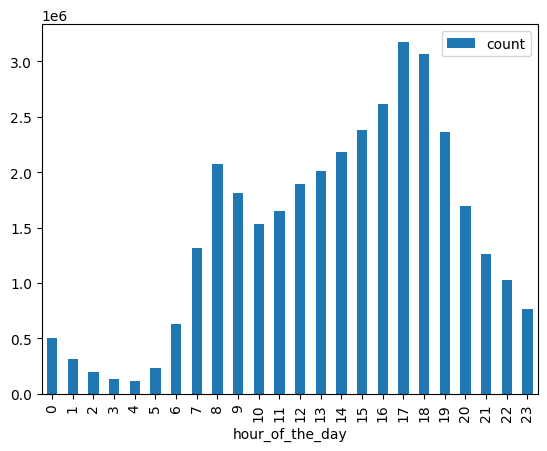

In [82]:
per_hour_df.toPandas().plot(kind='bar',x='hour_of_the_day',y='count')

+---------------+-------+
|day_of_the_week|  count|
+---------------+-------+
|              1|4292229|
|              2|4711350|
|              3|5262892|
|              4|5517047|
|              5|5417055|
|              6|5118942|
|              7|4628908|
+---------------+-------+



<Axes: xlabel='day_of_the_week'>

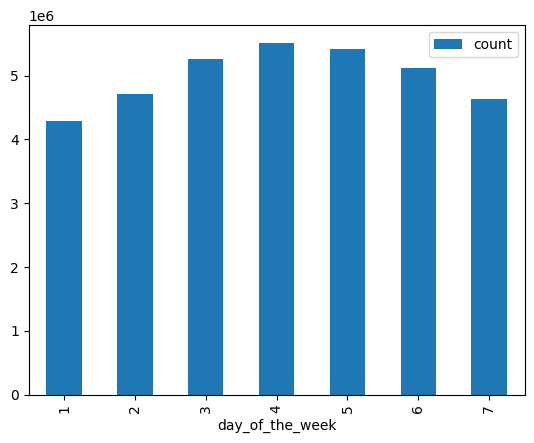

In [83]:

day_of_the_week_df = clean_consistent_df.withColumn('day_of_the_week',F.dayofweek(F.col('started_at')))\
                .groupby('day_of_the_week').count().sort(F.asc('day_of_the_week'))

day_of_the_week_df.show()

day_of_the_week_df.toPandas().plot(kind='bar',x='day_of_the_week',y='count')

+-----------------+-------+
|week_of_the_month|  count|
+-----------------+-------+
|                1|8101590|
|                2|8311030|
|                3|8344162|
|                4|7587206|
|                5|2604435|
+-----------------+-------+



<Axes: xlabel='week_of_the_month'>

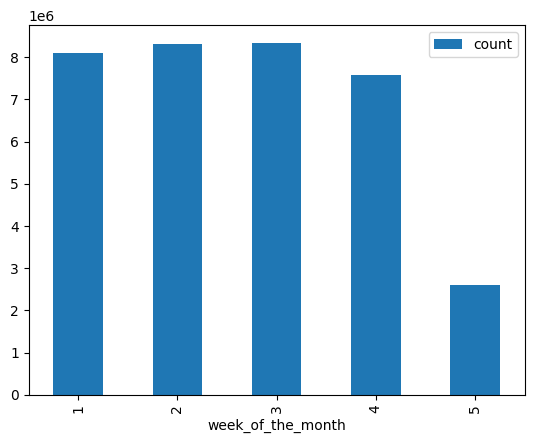

In [88]:

week_of_the_month_df = clean_consistent_df.withColumn('week_of_the_month',(((F.dayofmonth(F.col('started_at'))-1)/7)+1).cast('int'))\
                .groupby('week_of_the_month').count().sort(F.asc('week_of_the_month'))

week_of_the_month_df.show()

week_of_the_month_df.toPandas().plot(kind='bar',x='week_of_the_month',y='count')

2.5/7 ~= 0.35% , 8 * 2.5/7 ~= 2.8 which means it is correctly represented

+-----------------+-------+
|month_of_the_year|  count|
+-----------------+-------+
|                1|1788132|
|                2|1689574|
|                3|2111773|
|                4|2738302|
|                5|3440263|
|                6|3438841|
|                7|3644972|
|                8|3948090|
|                9|3450564|
|               10|3701643|
|               11|2800906|
|               12|2195363|
+-----------------+-------+



<Axes: xlabel='month_of_the_year'>

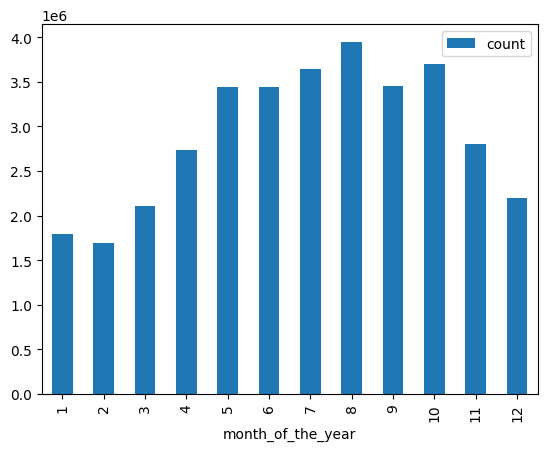

In [89]:
#first we do the per hour thing


month_of_the_year_df = clean_consistent_df.withColumn('month_of_the_year',F.month(F.col('started_at')))\
                .groupby('month_of_the_year').count().sort(F.asc('month_of_the_year'))

month_of_the_year_df.show()

month_of_the_year_df.toPandas().plot(kind='bar',x='month_of_the_year',y='count')

### Let's see which stations have the highest demande , and which station-2-station has the highest demande

In [127]:
pr_departure_station = clean_consistent_df.groupby('start_station_id').agg(
        F.count('*').alias('count'),
        F.first('start_station_name').alias('start_station_name'),
        F.avg('ride_duration').alias('avg_ride_duration'),
        F.avg('ride_distance').alias('avg_start_to_end_distance'),
).sort(F.desc('count'))
pr_departure_station.show(120,truncate=False)

+----------------+------+---------------------------------+------------------+-------------------------+
|start_station_id|count |start_station_name               |avg_ride_duration |avg_start_to_end_distance|
+----------------+------+---------------------------------+------------------+-------------------------+
|6140.05         |139495|W 21 St & 6 Ave                  |605.0547044696942 |1488.1274012688534       |
|6948.10         |115117|Broadway & W 58 St               |1005.6525187418018|1948.9641964262253       |
|5329.03         |110415|West St & Chambers St            |1029.9363854548749|2698.2804161572385       |
|5905.14         |107125|University Pl & E 14 St          |627.316098016336  |1460.996147024512        |
|6726.01         |106824|11 Ave & W 41 St                 |732.1144686587284 |1913.3446146932936       |
|6822.09         |104636|1 Ave & E 68 St                  |787.7320998509117 |2267.9736243740085       |
|6173.08         |102527|Broadway & W 25 St            

In [128]:
pr_arrival_station = clean_consistent_df.groupby('end_station_id').agg(
        F.count('*').alias('count'),
        F.first('end_station_name').alias('end_station_name'),
        F.avg('ride_duration').alias('avg_ride_duration'),
        F.avg('ride_distance').alias('avg_start_to_end_distance'),
).sort(F.desc('count'))
pr_arrival_station.show(120,truncate=False)

+--------------+------+---------------------------------+------------------+-------------------------+
|end_station_id|count |end_station_name                 |avg_ride_duration |avg_start_to_end_distance|
+--------------+------+---------------------------------+------------------+-------------------------+
|6140.05       |140240|W 21 St & 6 Ave                  |590.0842769537935 |1508.4262144181337       |
|6948.10       |112227|Broadway & W 58 St               |1094.2452796564107|1941.825442095025        |
|5329.03       |111206|West St & Chambers St            |1057.4219286729133|2803.279057245135        |
|5905.14       |109096|University Pl & E 14 St          |637.6137071936643 |1504.1531101965463       |
|6726.01       |107068|11 Ave & W 41 St                 |743.1557141256025 |1956.549967590692        |
|6822.09       |105330|1 Ave & E 68 St                  |751.9052881420298 |2330.565996866985        |
|6173.08       |102814|Broadway & W 25 St               |699.072966716595

In [126]:
pair_wise_station = clean_consistent_df.groupby('start_station_id','end_station_id').agg(
    F.count('*').alias('count'),
    F.avg('ride_duration').alias('avg_ride_duration'),
    F.avg('ride_distance').alias('avg_start_to_end_distance'),
    F.first('start_station_name').alias('start_station_name'),
    F.first('end_station_name').alias('end_station_name'),
).sort(F.desc('count'))
pair_wise_station.show(70,truncate=False)

+----------------+--------------+-----+------------------+-------------------------+---------------------------------------------+---------------------------------------------+
|start_station_id|end_station_id|count|avg_ride_duration |avg_start_to_end_distance|start_station_name                           |end_station_name                             |
+----------------+--------------+-----+------------------+-------------------------+---------------------------------------------+---------------------------------------------+
|6876.04         |6876.04       |11767|2159.54346902354  |0.0                      |Central Park S & 6 Ave                       |Central Park S & 6 Ave                       |
|6912.01         |6912.01       |11215|2458.0320998662505|0.0                      |7 Ave & Central Park South                   |7 Ave & Central Park South                   |
|6599.01         |6599.01       |7768 |2203.7929969104016|0.0                      |Roosevelt Island Tramway       

In [96]:
pair_wise_station.count()

1344603

In [97]:
pr_arrival_station.count()

2255

In [99]:
pr_departure_station.count()

2245

### Let's see how does weather affect ride demand
- join the data based on weather code
- aggregate demande for different weathers

In [ ]:
# Simple solution for skipping the 3 lines  :
weather_data_csv = '../data/nyc_weather_2023.csv';
weather_data_csv_skip_meta= '../data/nyc_weather_2023.csv'
with open(weather_data_csv,'r') as fin:
    data = fin.read().splitlines(True)
with open(weather_data_csv_skip_meta,'w+') as fout: 
    fout.writelines(data[3:])


# now reading the actual data
weather_df = spark.read.option("inferSchema","true").option('skipRows',3).option('header','true').csv(weather_data_csv_skip_meta)

weather_df.show(3)

+-------------------+-------------------+------------------------+-----------------------+-------------------------+------------------+---------+-------------+---------------------+
|               time|temperature_2m (°C)|relative_humidity_2m (%)|weather_code (wmo code)|apparent_temperature (°C)|precipitation (mm)|rain (mm)|snowfall (cm)|wind_speed_10m (km/h)|
+-------------------+-------------------+------------------------+-----------------------+-------------------------+------------------+---------+-------------+---------------------+
|2023-01-01 00:00:00|                8.9|                     100|                     51|                      7.0|               0.4|      0.4|          0.0|                 11.3|
|2023-01-01 01:00:00|               11.1|                     100|                     55|                      9.9|               1.1|      1.1|          0.0|                 10.4|
|2023-01-01 02:00:00|               11.1|                     100|                     53|

In [101]:
weather_df.printSchema()

root
 |-- time: timestamp (nullable = true)
 |-- temperature_2m (°C): double (nullable = true)
 |-- relative_humidity_2m (%): integer (nullable = true)
 |-- weather_code (wmo code): integer (nullable = true)
 |-- apparent_temperature (°C): double (nullable = true)
 |-- precipitation (mm): double (nullable = true)
 |-- rain (mm): double (nullable = true)
 |-- snowfall (cm): double (nullable = true)
 |-- wind_speed_10m (km/h): double (nullable = true)



In [114]:
# we join on the started_at_hour and join with the data from weather api
# add the cleaned/truncated hour to the left 'table'

lj_clean_consistent_df = clean_consistent_df.withColumn('ride_hour_join_key',F.date_trunc('hour',F.to_utc_timestamp('started_at','America/New_York')))

joined_df = lj_clean_consistent_df.join(
        weather_df,
        weather_df['time'] == lj_clean_consistent_df['ride_hour_join_key'],
        how='left'
)

In [115]:
joined_df.select('ride_id','started_at','start_station_id','weather_code (wmo code)').show(3,truncate=False)

+----------------+-----------------------+----------------+-----------------------+
|ride_id         |started_at             |start_station_id|weather_code (wmo code)|
+----------------+-----------------------+----------------+-----------------------+
|46025CEAA5B0DFD4|2023-05-07 20:39:58.519|6257.03         |3                      |
|B17C485C61781683|2023-05-10 17:17:10.865|6257.03         |0                      |
|535699AA49787159|2023-05-11 18:54:14.66 |6257.03         |0                      |
+----------------+-----------------------+----------------+-----------------------+
only showing top 3 rows


well we don't really understand 'the weather is 67' do we , this is the world meteo.. org , basically a standard/mapping of codes to weathers
we now craft a new column with things we can understand like rainy , snowy , 

In [116]:
# i dont want to rename the column because i am indexing it already with a og name
wc_key  = 'weather_code (wmo code)'
joined_df = joined_df.withColumn(
            'weather_desc',
            F.when(
                F.col(wc_key).between(0,3), 'Clear/Cloudy'
            ).when(
                F.col(wc_key).between(45,48),'Foggy'
            ).when(
                F.col(wc_key).between(51,57) | F.col(wc_key).between(61,63) ,'Normal Rain'
            ).when(
                F.col(wc_key).between(65,67) | F.col(wc_key).between(80,82) | F.col(wc_key).between(95,99) , 'High Rain'   
            ).when(
                F.col(wc_key).between(71,73) | (F.col(wc_key) == 77) | (F.col(wc_key) == 85)  , 'Normal Snow'
            ).when(
                (F.col(wc_key)==75) | (F.col(wc_key) == 86) , 'High Snow' 
            ).otherwise('UNKWN/DISASTER')
)

In [117]:
demande_per_weather = joined_df.groupby('weather_desc').agg(
    F.count('*').alias('count'),
).sort(F.desc('count'))

+--------------+--------+
|  weather_desc|   count|
+--------------+--------+
|  Clear/Cloudy|30490278|
|   Normal Rain| 4293241|
|   Normal Snow|  113605|
|     High Rain|   31906|
|UNKWN/DISASTER|   11009|
|     High Snow|    8384|
+--------------+--------+



<Axes: xlabel='weather_desc'>

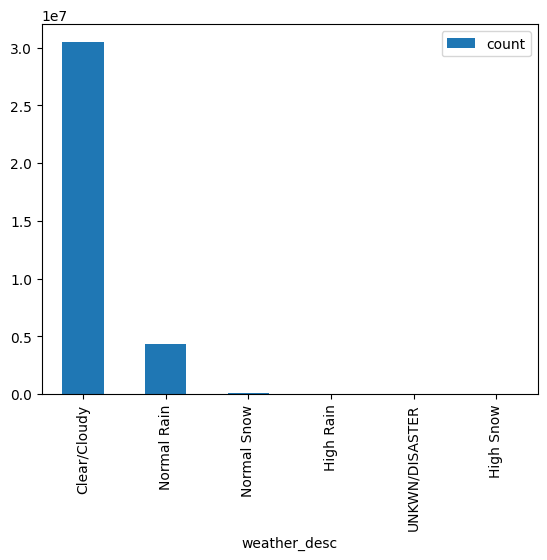

In [118]:
demande_per_weather.show()
demande_per_weather.toPandas().plot(kind='bar',x='weather_desc',y='count')

### hmmm it is extremly likely that the distrubution of the weather is skewing the distrubution of demand croos weather 

In [119]:
wc_key  = 'weather_code (wmo code)'
weather_df= weather_df.withColumn(
            'weather_desc',
            F.when(
                F.col(wc_key).between(0,3), 'Clear/Cloudy'
            ).when(
                F.col(wc_key).between(45,48),'Foggy'
            ).when(
                F.col(wc_key).between(51,57) | F.col(wc_key).between(61,63) ,'Normal Rain'
            ).when(
                F.col(wc_key).between(65,67) | F.col(wc_key).between(80,82) | F.col(wc_key).between(95,99) , 'High Rain'   
            ).when(
                F.col(wc_key).between(71,73) | (F.col(wc_key) == 77) | (F.col(wc_key) == 85)  , 'Normal Snow'
            ).when(
                (F.col(wc_key)==75) | (F.col(wc_key) == 86) , 'High Snow' 
            ).otherwise('UNKWN/DISASTER')
)

+------------+-----+
|weather_desc|count|
+------------+-----+
|Clear/Cloudy| 7406|
| Normal Rain| 1255|
| Normal Snow|   63|
|   High Rain|   28|
|   High Snow|    8|
+------------+-----+



<Axes: xlabel='weather_desc'>

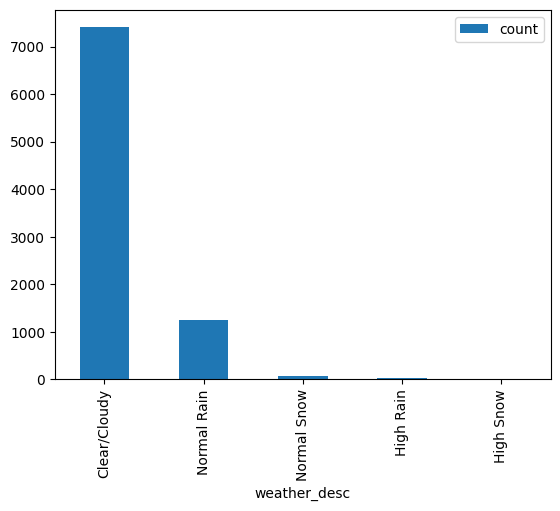

In [120]:
weather_distro = weather_df.groupby('weather_desc').agg(
    F.count('*').alias('count'),
).sort(F.desc('count'))

weather_distro.show()
weather_distro.toPandas().plot(kind='bar',x='weather_desc',y='count')

### we do some sort of normalization of demand across the time of resp weather desc
#### something like count of rides (demand) in that condition / hours of that condition 

+--------------+-----------+-----------+-------------+
|  weather_desc|total_rides|total_hours|rides_pr_hour|
+--------------+-----------+-----------+-------------+
|  Clear/Cloudy|   30490278|       7406|      4116.97|
|   Normal Rain|    4293241|       1255|      3420.91|
|   Normal Snow|     113605|         63|      1803.25|
|     High Rain|      31906|         28|       1139.5|
|     High Snow|       8384|          8|       1048.0|
|UNKWN/DISASTER|      11009|       NULL|         NULL|
+--------------+-----------+-----------+-------------+



<Axes: xlabel='weather_desc'>

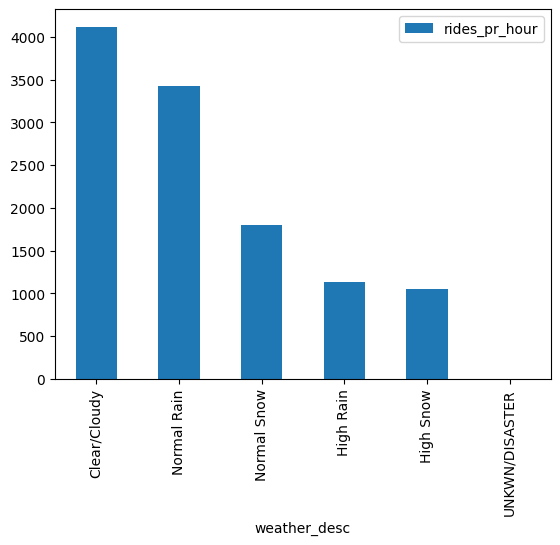

In [121]:
normalized_distro = demande_per_weather.withColumnRenamed('count','total_rides').join(
    weather_distro.withColumnRenamed('count','total_hours'),
    'weather_desc',
    how='LEFT'
).withColumn('rides_pr_hour',
             F.round(F.col('total_rides')/ F.col('total_hours') , 2)
).sort(
    F.desc(F.col('rides_pr_hour'))
)

normalized_distro.show()
normalized_distro.toPandas().plot(kind='bar',x='weather_desc',y='rides_pr_hour')

# Conclusions : 
### Demand Distrubution over time
across different `windows` of demand there were two patterns that were obvious  :
- across the hours of the day it seems like a GMM with mue1=8 and mue2=17 and the stdv2 seems bigger than stdv1
- across days of the week [1:sunday , 2:monday , ..] it seems the highest peak in wednesday (4) which is the middle of the week but the variation is questionable as is it uniform or normal distro
- across weeks of the month it is pretty much uniform , (the week 5 is special case explained above)
- across months of the year we notice a clear normal distrubition centered arround month 8 august , the summer , which means centered arround clear weather but that relation must be checked along weather data

### Demand between stations and station-pairs

we can notice a high demand on certain stations whether for departure or arrival and a gradual decrease of demand without sudden shift in the top 120 stations , for example the top 4 for both

    |6140.05       |140240 | W 21 St & 6 Ave

    |6948.10       |112227 | Broadway & W 58 St               

    |5329.03       |111206 | West St & Chambers St            

    |5905.14       |109096 | University Pl & E 14 St          


for the pairwise station one thing that is interesting is that the pairs with the HIGHEST demand are dominated by routes that start and end with the same station , which is quite revealing on the utility of those exact stations , for example : 

         |6876.04       |11767                      |Central Park S & 6 Ave                       |Central Park S & 6 Ave                       |
         |6912.01       |11215                      |7 Ave & Central Park South                   |7 Ave & Central Park South                   |




### Demand Across weather conditions
At first ,we can see after handling weather timezone casting to the same as citi-bike and aggregating demand based on weather conditions (using the codes of WMO) that there might be huge disproportionality and affect of climate on ride demands , but this change is actually linked to the natural skewed distrubution of weather ,  
The best way to combat this and see if there is actual impact we apply normalization with respect to the natural weather distrubution , and we can observe that : 
- the highest weighted demand is for clear/cloudy weather
- then the more the weather worsens the less demand per hour we have (from normal rain , normal snow , high rain ,high snow , disasters)